In [0]:
import pandas as pd
!pip install mlxtend
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_parquet("s3://e-commerce353/silver/events/")
df.head(5)

,event_id,timestamp,user_id,session_id,event_type,product_id,category,price,quantity,search_query,device,ingestion_timestamp,source_system,pipeline_version,event_date
0,be99def8-7ed7-4a76-8de8-28a401263a12,2026-03-28 15:27:13.352740,U000747,S0017844,product_view,P001292,Gaming,243.70,NaN,None,mobile,2026-10-09 14:23:03.164435,e-commerce353_events,1.0,2026-03-28
1,6394426f-4d2a-48b2-b7a2-c9b4cc089aad,2026-03-28 15:27:30.352740,U008010,S0064319,product_view,P000057,Gaming,451.11,NaN,None,desktop,2026-10-09 14:23:03.164435,e-commerce353_events,1.0,2026-03-28
2,fee7974a-96ac-41f1-9899-9ddeafe4bd68,2026-03-28 15:28:32.352740,U004666,S0060848,wishlist,P001789,Electronics,922.90,NaN,None,desktop,2026-10-09 14:23:03.164435,e-commerce353_events,1.0,2026-03-28
3,c2349f33-afde-41ec-a414-da3b2a163112,2026-03-28 15:29:38.352740,U000838,S0034841,purchase,P000078,Books,58.50,NaN,None,mobile,2026-10-09 14:23:03.164435,e-commerce353_events,1.0,2026-03-28
4,5b7bcea7-2299-44ed-afe0-47807a940428,2026-03-28 15:29:40.352740,U009191,S0035879,product_view,P001409,Beauty,51.58,NaN,None,tablet,2026-10-09 14:23:03.164435,e-commerce353_events,1.0,2026-03-28


In [0]:
# Create a deep copy of df to safely work with without affecting the original
df_copy = df.copy()

df_copy.head()


,event_id,timestamp,user_id,session_id,event_type,product_id,category,price,quantity,search_query,device,ingestion_timestamp,source_system,pipeline_version,event_date
0,be99def8-7ed7-4a76-8de8-28a401263a12,2026-03-28 15:27:13.352740,U000747,S0017844,product_view,P001292,Gaming,243.70,NaN,None,mobile,2026-10-09 14:23:03.164435,e-commerce353_events,1.0,2026-03-28
1,6394426f-4d2a-48b2-b7a2-c9b4cc089aad,2026-03-28 15:27:30.352740,U008010,S0064319,product_view,P000057,Gaming,451.11,NaN,None,desktop,2026-10-09 14:23:03.164435,e-commerce353_events,1.0,2026-03-28
2,fee7974a-96ac-41f1-9899-9ddeafe4bd68,2026-03-28 15:28:32.352740,U004666,S0060848,wishlist,P001789,Electronics,922.90,NaN,None,desktop,2026-10-09 14:23:03.164435,e-commerce353_events,1.0,2026-03-28
3,c2349f33-afde-41ec-a414-da3b2a163112,2026-03-28 15:29:38.352740,U000838,S0034841,purchase,P000078,Books,58.50,NaN,None,mobile,2026-10-09 14:23:03.164435,e-commerce353_events,1.0,2026-03-28
4,5b7bcea7-2299-44ed-afe0-47807a940428,2026-03-28 15:29:40.352740,U009191,S0035879,product_view,P001409,Beauty,51.58,NaN,None,tablet,2026-10-09 14:23:03.164435,e-commerce353_events,1.0,2026-03-28


In [0]:
# Columns in df_copy
df_copy.columns.tolist()

['event_id',
 'timestamp',
 'user_id',
 'session_id',
 'event_type',
 'product_id',
 'category',
 'price',
 'quantity',
 'search_query',
 'device',
 'ingestion_timestamp',
 'source_system',
 'pipeline_version',
 'event_date']

In [0]:
df_copy=df_copy.drop(['event_id',
 'timestamp',
 'session_id',
 'event_type',
 'price',
 'quantity',
 'search_query',
 'device',
 'ingestion_timestamp',
 'source_system',
 'pipeline_version',
 'event_date'],axis=1)

In [0]:
transaction_data = df_copy.groupby('user_id')
print("The transaction data is:")
print(transaction_data.head())


The transaction data is:
        user_id product_id     category
0       U000747    P001292       Gaming
1       U008010    P000057       Gaming
2       U004666    P001789  Electronics
3       U000838    P000078        Books
4       U009191    P001409       Beauty
...         ...        ...          ...
158048  U007326    P001802     Clothing
169639  U009623    P000205       Sports
175848  U000724    P001983  Electronics
184222  U009623    P000210     Clothing
197992  U007775    P001582        Books

[50000 rows x 3 columns]


In [0]:
transactions = transaction_data["category"].apply(list).tolist()
print("The transactions are:")
print(transactions[0:10])


The transactions are:
[['Home', 'Home', 'Electronics', 'Electronics', 'Electronics', 'Clothing', 'Home', 'Gaming', 'Home', 'Electronics', 'Gaming', 'Sports', 'Home', 'Sports', 'Clothing', 'Books', 'Gaming', 'Sports', 'Beauty', 'Electronics', 'Books', 'Sports', 'Electronics', 'Sports', 'Electronics', 'Sports', 'Clothing', 'Electronics', 'Electronics', 'Home', 'Clothing', 'Gaming', 'Books', 'Clothing', 'Gaming', 'Gaming', 'Gaming', 'Gaming', 'Electronics', 'Sports', 'Sports', 'Books', 'Beauty', 'Books', 'Books', 'Sports', 'Books', 'Books', 'Sports', 'Home', 'Sports', 'Books', 'Home', 'Beauty', 'Gaming', 'Beauty', 'Books', 'Gaming'], ['Home', 'Gaming', 'Books', 'Gaming', 'Electronics', 'Sports', 'Gaming', 'Sports', 'Gaming', 'Books', 'Books', 'Clothing', 'Gaming', 'Books', 'Gaming', 'Gaming', 'Beauty', 'Books', 'Beauty', 'Clothing', 'Books', 'Electronics', 'Books', 'Books', 'Beauty', 'Sports', 'Electronics', 'Gaming', 'Gaming', 'Beauty', 'Gaming', 'Gaming', 'Gaming', 'Beauty', 'Home', 'Be

In [0]:
transaction_encoder = TransactionEncoder()
transaction_array = transaction_encoder.fit(transactions).transform(transactions)
transaction_dataframe = pd.DataFrame(transaction_array, columns=transaction_encoder.columns_)
freuent_itemsets=fpgrowth(transaction_dataframe,min_support=0.02, use_colnames=True)
print("The frequent itemsets are:")
print(freuent_itemsets)

The frequent itemsets are:
     support                                           itemsets
0     0.9922                                             (Home)
1     0.9917                                           (Gaming)
2     0.9911                                           (Beauty)
3     0.9905                                      (Electronics)
4     0.9903                                            (Books)
..       ...                                                ...
122   0.9506     (Beauty, Books, Sports, Electronics, Clothing)
123   0.9441  (Books, Gaming, Sports, Electronics, Home, Clo...
124   0.9434  (Beauty, Books, Sports, Electronics, Home, Clo...
125   0.9427  (Beauty, Books, Gaming, Sports, Electronics, C...
126   0.9356  (Beauty, Books, Gaming, Sports, Electronics, H...

[127 rows x 2 columns]


In [0]:
association_rules_df=association_rules(freuent_itemsets, metric="confidence", min_threshold=.50)
print("The association rules are:")
print(association_rules_df.head())

The association rules are:
  antecedents consequents  antecedent support  ...   jaccard  certainty  kulczynski
0      (Home)    (Gaming)              0.9922  ...  0.984098   0.004282    0.991986
1    (Gaming)      (Home)              0.9917  ...  0.984098   0.004558    0.991986
2      (Home)    (Beauty)              0.9922  ...  0.983300  -0.007861    0.991580
3    (Beauty)      (Home)              0.9911  ...  0.983300  -0.008980    0.991580
4    (Beauty)    (Gaming)              0.9911  ...  0.982800  -0.008980    0.991325

[5 rows x 14 columns]


In [0]:
#selecting the main columns 
clean_rules = association_rules_df[[
    'antecedents',
    'consequents',
    'support',
    'confidence',
    'lift',
]]
# sorting lift
top_lift_rules = clean_rules.sort_values(by='lift', ascending=False)

#getting the top list
print(top_lift_rules.head(10))

/tmp/ipykernel_62/2890747680.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


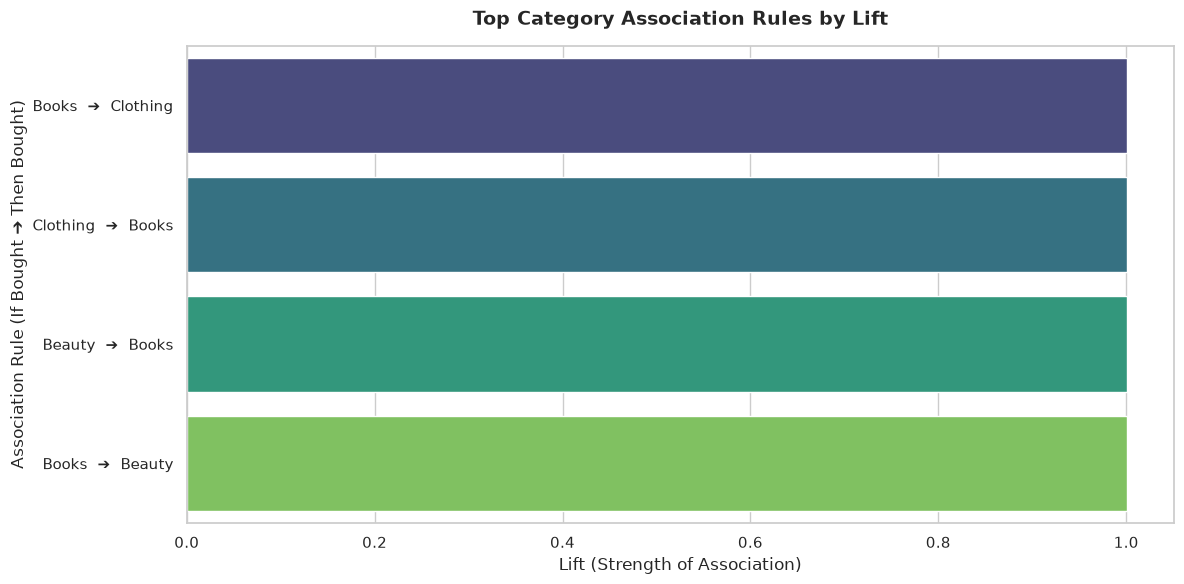

In [0]:

association_rules_df['rule_label'] = (
    association_rules_df['antecedents'].apply(lambda x: list(x)[0])
    + '  ➔  '
    + association_rules_df['consequents'].apply(lambda x: list(x)[0])
)

top_rules = association_rules_df.sort_values(by='lift', ascending=False).head(10)


plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=top_rules, x='lift', y='rule_label', palette='viridis'
)

plt.title(
    'Top Category Association Rules by Lift',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Lift (Strength of Association)', fontsize=12)
plt.ylabel('Association Rule (If Bought ➔ Then Bought)', fontsize=12)
plt.tight_layout()
plt.show()

In [0]:
df_product_pairs = pd.read_parquet(f"{GOLD_S3_PATH}product_cooccurrence/")
df_category_pairs = pd.read_parquet(f"{GOLD_S3_PATH}category_cooccurrence/")